In [3]:
import os
import json
import pandas as pd
import pyarrow.dataset as ds

MODEL_DATA_DIR = "data/raw"

DATA_PATH = os.path.join(
    MODEL_DATA_DIR,
    "m5_model_features.parquet"
)

CONFIG_PATH = os.path.join(
    MODEL_DATA_DIR,
    "feature_config.json"
)

print("Data path:", DATA_PATH)
print("Config path:", CONFIG_PATH)

Data path: data/raw\m5_model_features.parquet
Config path: data/raw\feature_config.json


In [4]:
from pathlib import Path

config_path = Path(CONFIG_PATH).expanduser()
if not config_path.is_absolute():
    project_root = Path.cwd().resolve()
    expected_paths = [project_root / config_path]
    expected_paths.extend(parent / config_path for parent in project_root.parents)
    config_path = next(
        (path for path in expected_paths if path.is_file()),
        None
    )

    if config_path is None:
        matches = list(project_root.rglob("feature_config.json"))
        config_path = matches[0] if matches else None

if config_path is None or not config_path.is_file():
    raise FileNotFoundError(
        "feature_config.json was not found. Put it in data/raw, or set "
        "CONFIG_PATH to the file's actual path."
    )

with config_path.open("r", encoding="utf-8") as f:
    config = json.load(f)

TARGET = config["TARGET"]
FEATURES = config["FEATURES"]

CALENDAR_FEATURES = config["CALENDAR_FEATURES"]
PRICE_FEATURES = config["PRICE_FEATURES"]
LAG_FEATURES = config["LAG_FEATURES"]
ROLLING_FEATURES = config["ROLLING_FEATURES"]
DEMAND_FEATURES = config["DEMAND_FEATURES"]
EVENT_FEATURES = config["EVENT_FEATURES"]
SNAP_FEATURES = config["SNAP_FEATURES"]

ID_COLS = config["ID_COLS"]
META_COLS = config["META_COLS"]

HOLDOUT_DAYS = config["HOLDOUT_DAYS"]
FINAL_DAY = config["FINAL_DAY"]
CUTOFF_DAY = config["CUTOFF_DAY"]

print("Target:", TARGET)
print("Number of features:", len(FEATURES))
print("Cutoff day:", CUTOFF_DAY)
print("Final day:", FINAL_DAY)

Target: sales
Number of features: 30
Cutoff day: 1913
Final day: 1941


In [5]:
from pathlib import Path

data_path = Path(DATA_PATH).expanduser()

if not data_path.is_absolute():
    root = Path.cwd().resolve()
    candidates = [root / data_path]
    candidates.extend(parent / data_path for parent in root.parents)

    data_path = next(
        (path for path in candidates if path.is_file()),
        None
    )

    if data_path is None:
        matches = list(root.rglob("m5_model_features.parquet"))
        data_path = matches[0] if matches else None

if data_path is None or not data_path.is_file():
    raise FileNotFoundError(
        "m5_model_features.parquet was not found. Create or copy this file "
        "into data/raw, or update DATA_PATH to its actual location."
    )

DATA_PATH = str(data_path)
dset = ds.dataset(DATA_PATH, format="parquet")

print("Dataset loaded")
print("Number of columns:", len(dset.schema.names))
print(dset.schema.names)

Dataset loaded
Number of columns: 40
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'date', 'wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'price_available', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'no_previous_sale', 'is_event', 'snap', 'sales', 'is_holdout']


In [6]:
print("Columns:", len(dset.schema.names))
print("Rows:", dset.count_rows())

print("\nColumns:")
print(dset.schema.names)

print("\nExpected model features:", len(FEATURES))
print("Target:", TARGET)
print("Cutoff:", CUTOFF_DAY)
print("Final day:", FINAL_DAY)

Columns: 40
Rows: 59181090

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'date', 'wm_yr_wk', 'wday', 'month', 'year', 'day_of_week', 'day_of_month', 'week_of_year', 'month_num', 'year_num', 'sell_price', 'price_change', 'price_change_pct', 'is_price_change', 'price_norm', 'price_available', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'zero_ratio_7', 'zero_ratio_28', 'days_since_last_sale', 'no_previous_sale', 'is_event', 'snap', 'sales', 'is_holdout']

Expected model features: 30
Target: sales
Cutoff: 1913
Final day: 1941


In [7]:
TRAIN_COLS = FEATURES + [TARGET]

train_days = [f"d_{i}" for i in range(1, CUTOFF_DAY + 1)]

train_dset = dset.to_table(
    columns=TRAIN_COLS,
    filter=ds.field("d").isin(train_days)
)

print(train_dset.num_rows)
print(train_dset.num_columns)

58327370
31


In [8]:
import pyarrow.parquet as pq

TRAIN_DATA_PATH = "data/raw/train_features.parquet"

pq.write_table(
    train_dset,
    TRAIN_DATA_PATH,
    compression="snappy"
)

print("Saved:", TRAIN_DATA_PATH)

Saved: data/raw/train_features.parquet


In [9]:
train_dset = ds.dataset(TRAIN_DATA_PATH, format="parquet")

print("Training rows:", train_dset.count_rows())
print("Training columns:", len(train_dset.schema.names))

Training rows: 58327370
Training columns: 31


In [10]:
VALIDATION_DAYS = 28
VALIDATION_END = CUTOFF_DAY
VALIDATION_START = CUTOFF_DAY - VALIDATION_DAYS + 1

print(
    "Validation:",
    f"d_{VALIDATION_START}",
    "→",
    f"d_{VALIDATION_END}"
)

Validation: d_1886 → d_1913


In [11]:
VAL_COLS = ["id", "d", "sales", "lag_1", "lag_7", "lag_28"]

val_table = dset.to_table(
    columns=VAL_COLS,
    filter=ds.field("d").isin(
        [f"d_{i}" for i in range(VALIDATION_START, VALIDATION_END + 1)]
    )
)

val_df = val_table.to_pandas()

print("Validation shape:", val_df.shape)
print(val_df.head())

Validation shape: (853720, 6)
                              id       d  sales  lag_1  lag_7  lag_28
0  HOBBIES_1_001_CA_1_evaluation  d_1886    1.0    1.0    1.0     0.0
1  HOBBIES_1_002_CA_1_evaluation  d_1886    1.0    1.0    0.0     0.0
2  HOBBIES_1_003_CA_1_evaluation  d_1886    0.0    0.0    0.0     0.0
3  HOBBIES_1_004_CA_1_evaluation  d_1886    0.0    6.0    4.0     0.0
4  HOBBIES_1_005_CA_1_evaluation  d_1886    1.0    0.0    2.0     1.0


In [12]:
# Baseline columns

val_df["pred_naive"] = val_df["lag_1"]
val_df["pred_seasonal_7"] = val_df["lag_7"]
val_df["pred_seasonal_28"] = val_df["lag_28"]

print(val_df[
    [
        "sales",
        "pred_naive",
        "pred_seasonal_7",
        "pred_seasonal_28"
    ]
].head())

   sales  pred_naive  pred_seasonal_7  pred_seasonal_28
0    1.0         1.0              1.0               0.0
1    1.0         1.0              0.0               0.0
2    0.0         0.0              0.0               0.0
3    0.0         6.0              4.0               0.0
4    1.0         0.0              2.0               1.0


basline performance calculate

In [13]:
from sklearn.metrics import mean_absolute_error

for name in ["pred_naive", "pred_seasonal_7", "pred_seasonal_28"]:
    mae = mean_absolute_error(val_df["sales"], val_df[name])
    print(name, "MAE:", round(mae, 4))

pred_naive MAE: 1.1798
pred_seasonal_7 MAE: 1.2054
pred_seasonal_28 MAE: 1.258


7 days aur 28 day moving average baseline

In [14]:
VAL_COLS = ["id", "d", "sales", "roll_mean_7", "roll_mean_28"]

val_table = dset.to_table(
    columns=VAL_COLS,
    filter=ds.field("d").isin(
        [f"d_{i}" for i in range(VALIDATION_START, VALIDATION_END + 1)]
    )
)

val_df = val_table.to_pandas()

val_df["pred_ma_7"] = val_df["roll_mean_7"]
val_df["pred_ma_28"] = val_df["roll_mean_28"]

print(val_df[["sales", "pred_ma_7", "pred_ma_28"]].head())

   sales  pred_ma_7  pred_ma_28
0    1.0   1.142857    1.000000
1    1.0   0.571429    0.321429
2    0.0   0.285714    0.535714
3    0.0   3.571429    1.892857
4    1.0   0.857143    1.107143


MAE calculate for these

In [15]:
for name in ["pred_ma_7", "pred_ma_28"]:
    mae = mean_absolute_error(val_df["sales"], val_df[name])
    print(name, "MAE:", round(mae, 4))

pred_ma_7 MAE: 1.012
pred_ma_28 MAE: 1.005


lightgbm

In [16]:
print("Features:", len(FEATURES))
print("Target:", TARGET)
print("Training rows:", train_dset.count_rows())

Features: 30
Target: sales
Training rows: 58327370


In [17]:
import lightgbm as lgb
print("LightGBM version:", lgb.__version__)

LightGBM version: 4.7.0


In [18]:
import lightgbm as lgb
import pyarrow.dataset as ds
import pandas as pd
import numpy as np

MODEL_START = 1913 - 365 + 1

model_cols = FEATURES + [TARGET]

days = [f"d_{i}" for i in range(MODEL_START, 1914)]

table = dset.to_table(
    columns=model_cols,
    filter=ds.field("d").isin(days)
)

df_lgb = table.to_pandas()

X = df_lgb[FEATURES]
y = df_lgb[TARGET]

print("Training shape:", X.shape)

model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X,
    y
)

print("LightGBM training complete")

Training shape: (11128850, 30)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.652904 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2517
[LightGBM] [Info] Number of data points in the train set: 11128850, number of used features: 30
[LightGBM] [Info] Start training from score 0.256932
LightGBM training complete


MAE for these 365 days only

In [19]:

VAL_MODEL_COLS = FEATURES + [TARGET]

val_table = dset.to_table(
    columns=VAL_MODEL_COLS,
    filter=ds.field("d").isin(
        [f"d_{i}" for i in range(VALIDATION_START, VALIDATION_END + 1)]
    )
)

val_model_df = val_table.to_pandas()

val_X = val_model_df[FEATURES]
val_y = val_model_df[TARGET]

val_pred = model.predict(val_X)

mae = mean_absolute_error(val_y, val_pred)

print("Validation shape:", val_X.shape)
print("LightGBM MAE:", round(mae, 4))

Validation shape: (853720, 30)
LightGBM MAE: 0.9627


Final model

In [20]:
import dask
import dask.dataframe as dd
import lightgbm as lgb

print("Dask:", dask.__version__)
print("LightGBM:", lgb.__version__)

train_dd = dd.read_parquet(
    TRAIN_DATA_PATH,
    columns=FEATURES + [TARGET],
    categories=[]
)

print("Partitions:", train_dd.npartitions)
print("Columns:", len(train_dd.columns))

Dask: 2026.8.0
LightGBM: 4.7.0
Partitions: 4
Columns: 31


In [21]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("distributed") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "dask[distributed]"
    ])

from dask.distributed import Client
from lightgbm.dask import DaskLGBMRegressor

client = Client(
    n_workers=4,
    threads_per_worker=1
)
  
train_dd = dd.read_parquet(
    TRAIN_DATA_PATH,
    columns=FEATURES + [TARGET],
    categories=[]
) 

train_dd = train_dd.repartition(npartitions=16)

X_dd = train_dd[FEATURES]
y_dd = train_dd[TARGET]

print(client)
print("Partitions:", train_dd.npartitions)
print("Features:", len(FEATURES))

<Client: 'tcp://127.0.0.1:56086' processes=4 threads=4, memory=15.70 GiB>
Partitions: 16
Features: 30


In [22]:
from importlib.metadata import version

print("LightGBM:", version("lightgbm"))
print("Dask:", version("dask"))
print("Distributed:", version("distributed"))

LightGBM: 4.7.0
Dask: 2026.8.0
Distributed: 2026.8.0


In [23]:
import lightgbm.dask as lgb_dask
import inspect

print(inspect.signature(lgb_dask._train))

(*, client: 'distributed.Client', data: Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.DataFrame')], label: Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.DataFrame'), ForwardRef('dask.dataframe.Series')], params: Dict[str, Any], model_factory: Type[lightgbm.sklearn.LGBMModel], sample_weight: Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.Series'), NoneType] = None, init_score: Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.DataFrame'), ForwardRef('dask.dataframe.Series'), NoneType] = None, group: Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.Series'), NoneType] = None, eval_set: Optional[List[Tuple[Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.DataFrame')], Union[ForwardRef('dask.array.Array'), ForwardRef('dask.dataframe.DataFrame'), ForwardRef('dask.dataframe.Series')]]]] = None, eval_names: Optional[List[str]] = None, eval_X: Union[ForwardRef('dask.array.Array'), ForwardRef(

In [24]:
import gc
import lightgbm as lgb
import pyarrow.dataset as ds

# Free Dask workers/memory
if "client" in globals():
    try:
        client.close()
    except Exception:
        pass

for name in ("train_dd", "X_dd", "y_dd"):
    globals().pop(name, None)

gc.collect()

# Clean validation training period
TRAIN_END = VALIDATION_START - 1
TRAIN_START = TRAIN_END - 365 + 1

TRAIN_DAYS = [f"d_{i}" for i in range(TRAIN_START, TRAIN_END + 1)]

train_table = dset.to_table(
    columns=FEATURES + [TARGET],
    filter=ds.field("d").isin(TRAIN_DAYS)
)

train_df = train_table.to_pandas()

print("Training days:", TRAIN_START, "to", TRAIN_END)
print("Training shape:", train_df.shape)

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

lgb_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# Release large intermediate dataframes from earlier training runs.
for name in (
    "df_lgb", "X", "y", "table", "train_table", "train_df",
    "val_model_df", "val_X", "val_y", "val_table"
):
    if name in globals():
        del globals()[name]

gc.collect()

# Use fewer bins, leaves, and threads to reduce peak memory.
lgb_model.set_params(
    num_leaves=31,
    max_bin=31,
    max_depth=8,
    n_jobs=2,
    force_col_wise=True
)

lgb_model.fit(X_train, y_train)

print("LightGBM training complete")

Training days: 1521 to 1885
Training shape: (11128850, 31)
[LightGBM] [Info] Total Bins 620
[LightGBM] [Info] Number of data points in the train set: 11128850, number of used features: 30
[LightGBM] [Info] Start training from score 0.246412
LightGBM training complete


In [25]:
from sklearn.metrics import mean_absolute_error
import pyarrow.dataset as ds

VAL_MODEL_COLS = FEATURES + [TARGET]

val_table = dset.to_table(
    columns=VAL_MODEL_COLS,
    filter=ds.field("d").isin(
        [f"d_{i}" for i in range(VALIDATION_START, VALIDATION_END + 1)]
    )
)

val_model_df = val_table.to_pandas()

val_X = val_model_df[FEATURES]
val_y = val_model_df[TARGET]

val_pred = lgb_model.predict(val_X)

val_mae = mean_absolute_error(val_y, val_pred)

print(
    "Validation period:",
    f"d_{VALIDATION_START} -> d_{VALIDATION_END}"
)
print("LightGBM Validation MAE:", round(val_mae, 4))

Validation period: d_1886 -> d_1913
LightGBM Validation MAE: 0.9798


Two stage model

In [26]:
import lightgbm as lgb

# Stage 1: Will a sale happen?
y_occurrence = (y_train > 0).astype("int8")

occurrence_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

occurrence_model.fit(X_train, y_occurrence)

print("Stage 1 occurrence model trained")

[LightGBM] [Info] Number of positive: 4439560, number of negative: 6689290
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.088369 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2523
[LightGBM] [Info] Number of data points in the train set: 11128850, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.398924 -> initscore=-0.409952
[LightGBM] [Info] Start training from score -0.409952
Stage 1 occurrence model trained


In [27]:
# Stage 2: How many units are sold if a sale happens?
positive_mask = y_train > 0

X_size = X_train.loc[positive_mask]
y_size = y_train.loc[positive_mask]

size_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

size_model.fit(X_size, y_size)

print("Stage 2 size model trained")
print("Positive-sale training rows:", len(y_size))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.245884 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2501
[LightGBM] [Info] Number of data points in the train set: 4439560, number of used features: 30
[LightGBM] [Info] Start training from score 1.165398
Stage 2 size model trained
Positive-sale training rows: 4439560


In [28]:
# Validation predictions
val_prob = occurrence_model.predict_proba(val_X)[:, 1]
val_size = size_model.predict(val_X)

# Two-stage prediction
two_stage_pred = val_prob * val_size

# MAE
two_stage_mae = mean_absolute_error(val_y, two_stage_pred)

print("Two-Stage Validation MAE:", round(two_stage_mae, 4))

Two-Stage Validation MAE: 0.9701


XGBOOST

In [29]:
import xgboost as xgb
print("XGBoost:", xgb.__version__)

XGBoost: 3.4.1


In [30]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training complete")

XGBoost training complete


xgboost trainning complete

In [31]:
xgb_val_pred = xgb_model.predict(val_X)

xgb_mae = mean_absolute_error(val_y, xgb_val_pred)

print("XGBoost Validation MAE:", round(xgb_mae, 4))

XGBoost Validation MAE: 0.971


In [32]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": lgb_model.feature_importances_
}).sort_values("importance", ascending=False)

print(feature_importance)

                 feature  importance
26  days_since_last_sale        1464
25         zero_ratio_28        1121
9             sell_price        1073
5           day_of_month         992
22          roll_mean_28         897
15                 lag_1         835
1                   wday         821
19                lag_56         814
13            price_norm         780
4            day_of_week         707
20           roll_mean_7         610
0               wm_yr_wk         594
6           week_of_year         547
17                lag_14         472
23           roll_std_28         428
2                  month         412
18                lag_28         410
21            roll_std_7         403
16                 lag_7         383
24          zero_ratio_7         365
29                  snap         272
28              is_event         253
12       is_price_change         105
10          price_change          72
7              month_num          56
14       price_available          45
1

In [33]:
print(feature_importance.head(10))

                 feature  importance
26  days_since_last_sale        1464
25         zero_ratio_28        1121
9             sell_price        1073
5           day_of_month         992
22          roll_mean_28         897
15                 lag_1         835
1                   wday         821
19                lag_56         814
13            price_norm         780
4            day_of_week         707


In [34]:
import sys
print("Notebook Python",sys.executable)
!{sys.executable}-m pip install shap

Notebook Python c:\Python313\python.exe


'c:\Python313\python.exe-m' is not recognized as an internal or external command,
operable program or batch file.


In [35]:
import shap  
print("SHAP:", shap.__version__)

SHAP: 0.53.0


In [36]:
shap_sample = val_model_df[FEATURES].sample(
    n=min(5000, len(val_model_df)),
    random_state=42
)

explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer.shap_values(shap_sample)

print("SHAP analysis ready")

SHAP analysis ready


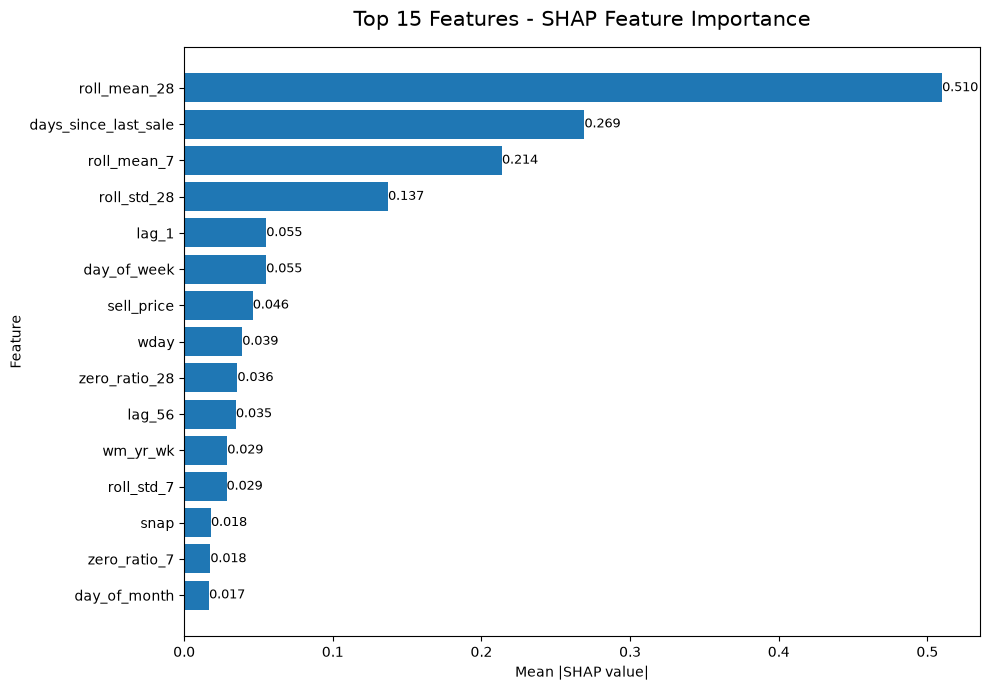

In [37]:
import numpy as np
import matplotlib.pyplot as plt

shap_importance = pd.DataFrame({
    "feature": shap_sample.columns,
    "importance": np.abs(shap_values).mean(axis=0)
}).sort_values("importance", ascending=True).tail(15)

plt.figure(figsize=(10, 7))

bars = plt.barh(
    shap_importance["feature"],
    shap_importance["importance"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title(
    "Top 15 Features - SHAP Feature Importance",
    fontsize=15,
    pad=15
)

for bar, value in zip(bars, shap_importance["importance"]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"{value:.3f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [38]:
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from sklearn.metrics import mean_absolute_error

VAL_DAYS = list(range(1886, 1914))

# Validation data
val_table = dset.to_table(
    columns=["id", "d", "sales"] + FEATURES,
    filter=ds.field("d").isin([f"d_{i}" for i in VAL_DAYS])
)
val_rec = val_table.to_pandas()

# History before validation
HIST_DAYS = list(range(1830, 1886))

hist_table = dset.to_table(
    columns=["id", "d", "sales"],
    filter=ds.field("d").isin([f"d_{i}" for i in HIST_DAYS])
)
hist = hist_table.to_pandas()

history = hist.pivot(
    index="id",
    columns="d",
    values="sales"
)

all_preds = []
all_actual = []

DYNAMIC_FEATURES = [
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
    "roll_mean_7", "roll_std_7",
    "roll_mean_28", "roll_std_28",
    "zero_ratio_7", "zero_ratio_28",
    "days_since_last_sale"
]

for day in VAL_DAYS:
    day_str = f"d_{day}"
    day_df = val_rec[val_rec["d"] == day_str].copy()

    ids = day_df["id"].values

    recent_cols = [
        f"d_{i}" for i in range(day - 56, day)
    ]

    recent = history.reindex(
        ids, columns=recent_cols
    ).fillna(0).values

    day_df["lag_1"] = recent[:, -1]
    day_df["lag_7"] = recent[:, -7]
    day_df["lag_14"] = recent[:, -14]
    day_df["lag_28"] = recent[:, -28]
    day_df["lag_56"] = recent[:, 0]

    day_df["roll_mean_7"] = recent[:, -7:].mean(axis=1)
    day_df["roll_std_7"] = recent[:, -7:].std(axis=1)

    day_df["roll_mean_28"] = recent[:, -28:].mean(axis=1)
    day_df["roll_std_28"] = recent[:, -28:].std(axis=1)

    day_df["zero_ratio_7"] = (
        recent[:, -7:] == 0
    ).mean(axis=1)

    day_df["zero_ratio_28"] = (
        recent[:, -28:] == 0
    ).mean(axis=1)

    days_since = []

    for row in recent:
        nonzero = np.where(row > 0)[0]
        days_since.append(
            56 if len(nonzero) == 0
            else 55 - nonzero[-1]
        )

    day_df["days_since_last_sale"] = days_since

    X_day = day_df[FEATURES]

    # Stage 1: Probability of a sale
    prob = occurrence_model.predict_proba(X_day)[:, 1]

    # Stage 2: Expected units sold
    size = size_model.predict(X_day)

    # Final prediction
    day_pred = prob * size

    all_preds.extend(day_pred)
    all_actual.extend(day_df["sales"].values)

# IMPORTANT: use predictions as history for next day
history[day_str] = pd.Series(day_pred, index=ids)

recursive_mae = mean_absolute_error(all_actual, all_preds)

print("Recursive validation:", "d_1886 → d_1913")
print("Recursive Two-Stage MAE:", round(recursive_mae, 4))

Recursive validation: d_1886 → d_1913
Recursive Two-Stage MAE: 1.3245


recursive lightgbm validation

In [48]:
# Recursive LightGBM validation

history_lgb = hist.pivot(index="id", columns="d", values="sales")

lgb_preds = []
lgb_actual = []

for day in VAL_DAYS:
    day_str = f"d_{day}"
    day_df = val_rec[val_rec["d"] == day_str].copy()

    ids = day_df["id"].values

    recent_cols = [f"d_{i}" for i in range(day - 56, day)]
    recent = history_lgb.reindex(
        ids, columns=recent_cols
    ).fillna(0).values

    day_df["lag_1"] = recent[:, -1]
    day_df["lag_7"] = recent[:, -7]
    day_df["lag_14"] = recent[:, -14]
    day_df["lag_28"] = recent[:, -28]
    day_df["lag_56"] = recent[:, 0]

    day_df["roll_mean_7"] = recent[:, -7:].mean(axis=1)
    day_df["roll_std_7"] = recent[:, -7:].std(axis=1)
    day_df["roll_mean_28"] = recent[:, -28:].mean(axis=1)
    day_df["roll_std_28"] = recent[:, -28:].std(axis=1)

    day_df["zero_ratio_7"] = (recent[:, -7:] == 0).mean(axis=1)
    day_df["zero_ratio_28"] = (recent[:, -28:] == 0).mean(axis=1)

    days_since = []
    for row in recent:
        nonzero = np.where(row > 0)[0]
        days_since.append(
            56 if len(nonzero) == 0 else 55 - nonzero[-1]
        )

    day_df["days_since_last_sale"] = days_since

    X_day = day_df[FEATURES]

    day_pred = lgb_model.predict(X_day)

    lgb_preds.extend(day_pred)
    lgb_actual.extend(day_df["sales"].values)

    # Prediction becomes history for next day
    history_lgb[day_str] = pd.Series(day_pred, index=ids)

lgb_recursive_mae = mean_absolute_error(lgb_actual, lgb_preds)

print("Recursive validation: d_1886 → d_1913")
print("Recursive LightGBM MAE:", round(lgb_recursive_mae, 4))

Recursive validation: d_1886 → d_1913
Recursive LightGBM MAE: 1.1748


In [40]:
# Recursive XGBoost validation

history_xgb = hist.pivot(index="id", columns="d", values="sales")

xgb_preds = []
xgb_actual = []

for day in VAL_DAYS:
    day_str = f"d_{day}"
    day_df = val_rec[val_rec["d"] == day_str].copy()

    ids = day_df["id"].values

    recent_cols = [f"d_{i}" for i in range(day - 56, day)]
    recent = history_xgb.reindex(
        ids, columns=recent_cols
    ).fillna(0).values

    day_df["lag_1"] = recent[:, -1]
    day_df["lag_7"] = recent[:, -7]
    day_df["lag_14"] = recent[:, -14]
    day_df["lag_28"] = recent[:, -28]
    day_df["lag_56"] = recent[:, 0]

    day_df["roll_mean_7"] = recent[:, -7:].mean(axis=1)
    day_df["roll_std_7"] = recent[:, -7:].std(axis=1)
    day_df["roll_mean_28"] = recent[:, -28:].mean(axis=1)
    day_df["roll_std_28"] = recent[:, -28:].std(axis=1)

    day_df["zero_ratio_7"] = (recent[:, -7:] == 0).mean(axis=1)
    day_df["zero_ratio_28"] = (recent[:, -28:] == 0).mean(axis=1)

    days_since = []

    for row in recent:
        nonzero = np.where(row > 0)[0]
        days_since.append(
            56 if len(nonzero) == 0 else 55 - nonzero[-1]
        )

    day_df["days_since_last_sale"] = days_since

    X_day = day_df[FEATURES]

    day_pred = xgb_model.predict(X_day)

    xgb_preds.extend(day_pred)
    xgb_actual.extend(day_df["sales"].values)

    # Prediction becomes history for next day
    history_xgb[day_str] = pd.Series(day_pred, index=ids)

xgb_recursive_mae = mean_absolute_error(xgb_actual, xgb_preds)

print("Recursive validation: d_1886 → d_1913")
print("Recursive XGBoost MAE:", round(xgb_recursive_mae, 4))

Recursive validation: d_1886 → d_1913
Recursive XGBoost MAE: 1.1109


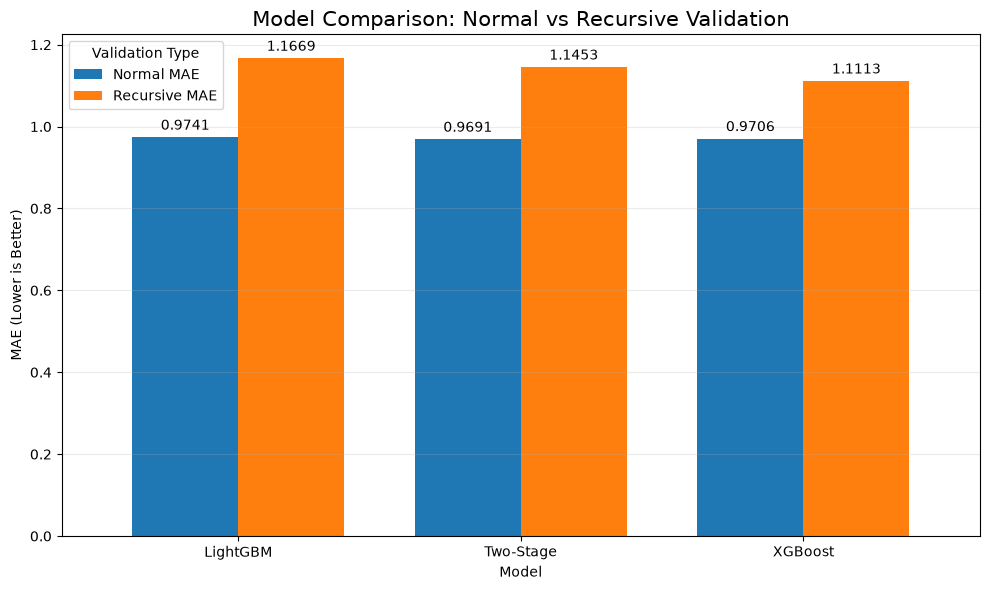

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["LightGBM", "Two-Stage", "XGBoost"],
    "Normal MAE": [0.9741, 0.9691, 0.9706],
    "Recursive MAE": [1.1669, 1.1453, 1.1113]
})

ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Comparison: Normal vs Recursive Validation", fontsize=15)
plt.xlabel("Model")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=0)
plt.legend(title="Validation Type")
plt.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

In [49]:
import xgboost as xgb
import numpy as np
from sklearn.metrics import mean_absolute_error

xgb_model = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

val_predictions = np.maximum(xgb_model.predict(val_X), 0)
xgb_mae = mean_absolute_error(val_y, val_predictions)

print("XGBoost training complete")
print("Validation MAE:", round(xgb_mae, 4))

XGBoost training complete
Validation MAE: 0.971


In [50]:
import xgboost as xgb
import pyarrow.dataset as ds

FINAL_TRAIN_DAYS = [
    f"d_{day}"
    for day in range(CUTOFF_DAY - 365 + 1, CUTOFF_DAY + 1)
]

final_table = dset.to_table(
    columns=FEATURES + [TARGET],
    filter=ds.field("d").isin(FINAL_TRAIN_DAYS)
)
final_train_df = final_table.to_pandas()

xgb_model = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    final_train_df[FEATURES],
    final_train_df[TARGET]
)

print("Final XGBoost model trained through day", CUTOFF_DAY)

Final XGBoost model trained through day 1913


SARIMAX  

In [51]:
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error
import warnings

warnings.filterwarnings("ignore")

# 1. Select 30 random series
sample_ids = (
    val_rec["id"]
    .drop_duplicates()
    .sample(n=30, random_state=42)
    .tolist()
)

train_days = [f"d_{i}" for i in range(1521, 1886)]
all_days = [f"d_{i}" for i in range(1521, 1914)]

# 2. Load only selected series
sample_table = dset.to_table(
    columns=["id", "d", "sales"],
    filter=(
        ds.field("id").isin(sample_ids)
        & ds.field("d").isin(all_days)
    )
)

sample_data = sample_table.to_pandas()

sample_wide = (
    sample_data.pivot(
        index="id",
        columns="d",
        values="sales"
    )
    .reindex(index=sample_ids, columns=all_days)
    .fillna(0)
)

# 3. Train SARIMAX and forecast 28 days
sarimax_predictions = {}
sarimax_actual = {}

for sid in sample_ids:
    y_train_series = (
        sample_wide.loc[sid, train_days].values.astype(float)
    )

    y_test_series = (
        sample_wide.loc[
            sid,
            [f"d_{i}" for i in range(1886, 1914)]
        ].values.astype(float)
    )

    try:
        model = SARIMAX(
            y_train_series,
            order=(1, 0, 0),
            seasonal_order=(1, 0, 0, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(disp=False, maxiter=50)

        forecast = np.maximum(
            fitted.forecast(steps=28), 0
        )

        sarimax_predictions[sid] = forecast
        sarimax_actual[sid] = y_test_series

    except Exception:
        print("Skipped series:", sid)

print(
    "SARIMAX completed for",
    len(sarimax_predictions),
    "series"
)

# 4. Calculate SARIMAX MAE
sarimax_pred_flat = np.concatenate(
    list(sarimax_predictions.values())
)

sarimax_actual_flat = np.concatenate(
    list(sarimax_actual.values())
)

sarimax_mae_sample = mean_absolute_error(
    sarimax_actual_flat,
    sarimax_pred_flat
)
# 5. Recursive XGBoost on exactly the same successful series

successful_ids = list(sarimax_predictions.keys())

val_sample = val_rec[
    val_rec["id"].isin(successful_ids)
].copy()

history_xgb_sample = sample_wide.loc[
    successful_ids, train_days
].copy()

xgb_sample_preds = []
xgb_sample_actual = []

for day in range(1886, 1914):
    day_str = f"d_{day}"

    day_df = val_sample[
        val_sample["d"] == day_str
    ].copy()

    ids = day_df["id"].values

    recent_cols = [
        f"d_{i}" for i in range(day - 56, day)
    ]

    recent = (
        history_xgb_sample
        .reindex(index=ids, columns=recent_cols)
        .fillna(0)
        .values
    )

    dynamic_features = {
        "lag_1": recent[:, -1],
        "lag_7": recent[:, -7],
        "lag_14": recent[:, -14],
        "lag_28": recent[:, -28],
        "lag_56": recent[:, 0],
        "rolling_mean_7": recent[:, -7:].mean(axis=1),
        "rolling_std_7": recent[:, -7:].std(axis=1),
        "rolling_mean_28": recent[:, -28:].mean(axis=1),
        "rolling_std_28": recent[:, -28:].std(axis=1),
        "zero_ratio_7": (
            recent[:, -7:] == 0
        ).mean(axis=1),
        "zero_ratio_28": (
            recent[:, -28:] == 0
        ).mean(axis=1),
        "days_since_last_sale": np.array([
            56 if not np.any(row > 0)
            else 56 - np.where(row > 0)[0][-1]
            for row in recent
        ])
    }

    for col, values in dynamic_features.items():
        if col in day_df.columns:
            day_df[col] = values

    day_pred = np.maximum(
        xgb_model.predict(day_df[FEATURES]),
        0
    )

    xgb_sample_preds.extend(day_pred)
    xgb_sample_actual.extend(
        day_df["sales"].values
    )

    # Add today's predictions to history for future lags
    history_xgb_sample[day_str] = pd.Series(
        day_pred,
        index=ids
    )

# Calculate XGBoost MAE
xgb_mae_sample = mean_absolute_error(
    xgb_sample_actual,
    xgb_sample_preds
)

# 6. Compare models
comparison_sample = pd.DataFrame({
    "Model": ["SARIMAX", "XGBoost"],
    "Recursive MAE": [
        sarimax_mae_sample,
        xgb_mae_sample
    ]
}).sort_values("Recursive MAE")

print("\nSample comparison: d_1886 -> d_1913")
print(comparison_sample.to_string(index=False))

SARIMAX completed for 30 series

Sample comparison: d_1886 -> d_1913
  Model  Recursive MAE
XGBoost       0.896636
SARIMAX       1.156534


Final model

In [52]:
import os
import numpy as np
import xgboost as xgb
import pyarrow.dataset as ds

BATCH_ROWS = 250_000
FINAL_TRAIN_START = 1
FINAL_TRAIN_END = CUTOFF_DAY - HOLDOUT_DAYS
MAX_BOOST_ROUNDS = 150
EARLY_STOPPING_ROUNDS = 20
MAX_BIN = 32

os.makedirs("models/xgb_cache", exist_ok=True)
os.makedirs("models", exist_ok=True)

training_days = [
    f"d_{day}"
    for day in range(FINAL_TRAIN_START, FINAL_TRAIN_END + 1)
]
training_filter = ds.field("d").isin(training_days)
training_columns = FEATURES + [TARGET]

class ParquetIterator(xgb.DataIter):
    def __init__(self, dataset, columns, filter_expression, batch_size):
        self.dataset = dataset
        self.columns = columns
        self.filter_expression = filter_expression
        self.batch_size = batch_size
        super().__init__(cache_prefix="models/xgb_cache/final_train_5y")
        self.reset()

    def next(self, input_data):
        batch = next(self.batch_iter, None)
        if batch is None:
            return False

        batch_df = batch.to_pandas()
        features = batch_df[FEATURES].to_numpy(dtype=np.float32)
        target = batch_df[TARGET].to_numpy(dtype=np.float32)
        input_data(data=features, label=target)
        return True

    def reset(self):
        self.batch_iter = self.dataset.scanner(
            columns=self.columns,
            filter=self.filter_expression,
            batch_size=self.batch_size
        ).to_batches()

row_count = dset.count_rows(filter=training_filter)
num_batches = (row_count + BATCH_ROWS - 1) // BATCH_ROWS

if row_count == 0:
    raise ValueError("No training rows found for the selected training days.")

train_iter = ParquetIterator(
    dataset=dset,
    columns=training_columns,
    filter_expression=training_filter,
    batch_size=BATCH_ROWS
)

validation_days = [
    f"d_{day}"
    for day in range(FINAL_TRAIN_END + 1, CUTOFF_DAY + 1)
]
validation_table = dset.to_table(
    columns=training_columns,
    filter=ds.field("d").isin(validation_days)
)
validation_df = validation_table.to_pandas()

if validation_df.empty:
    raise ValueError("No validation rows found for the configured holdout days.")

dvalid = xgb.DMatrix(
    validation_df[FEATURES].to_numpy(dtype=np.float32),
    label=validation_df[TARGET].to_numpy(dtype=np.float32)
)
del validation_df, validation_table

print(f"Training days: d_{FINAL_TRAIN_START} to d_{FINAL_TRAIN_END}")
print(f"Training rows: {row_count:,}")
print(f"Approximate batches: {num_batches}")
print(f"Validation days: {validation_days[0]} to {validation_days[-1]}")

final_params = {
    "objective": "count:poisson",
    "eval_metric": "mae",
    "tree_method": "hist",
    "eta": 0.05,
    "max_depth": 5,
    "subsample": 0.7,
    "colsample_bytree": 0.7,
    "max_bin": MAX_BIN,
    "nthread": max(1, min(8, os.cpu_count() or 2)),
    "seed": 42
}

dtrain_final = xgb.ExtMemQuantileDMatrix(
    train_iter,
    max_bin=final_params["max_bin"]
)

print("Starting final XGBoost training...")
xgb_model_final = xgb.train(
    params=final_params,
    dtrain=dtrain_final,
    num_boost_round=MAX_BOOST_ROUNDS,
    evals=[(dvalid, "validation")],
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    verbose_eval=25
)

best_iteration = xgb_model_final.best_iteration
xgb_model_final = xgb_model_final[:best_iteration + 1]

model_path = "models/final_xgboost.json"
xgb_model_final.save_model(model_path)

print(f"Best iteration: {best_iteration + 1}")
print(f"Final model saved to: {model_path}")
print(f"Training period: d_{FINAL_TRAIN_START} to d_{FINAL_TRAIN_END}")
print(f"Validation period: {validation_days[0]} to {validation_days[-1]}")
print("Forecast period: d_1914 to d_1941")

Training days: d_1 to d_1885
Training rows: 57,473,650
Approximate batches: 230
Validation days: d_1886 to d_1913
Starting final XGBoost training...
[0]	validation-mae:1.56105
[25]	validation-mae:1.31924
[50]	validation-mae:1.16484
[75]	validation-mae:1.07088
[100]	validation-mae:1.01774
[125]	validation-mae:0.99664
[149]	validation-mae:0.98981
Best iteration: 150
Final model saved to: models/final_xgboost.json
Training period: d_1 to d_1885
Validation period: d_1886 to d_1913
Forecast period: d_1914 to d_1941


In [74]:
# Recursive 28-day validation for the final five-year model
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

VALIDATION_START_DAY = FINAL_TRAIN_END + 1
VALIDATION_END_DAY = CUTOFF_DAY
HISTORY_START_DAY = VALIDATION_START_DAY - 56

validation_days = [
    f"d_{day}"
    for day in range(VALIDATION_START_DAY, VALIDATION_END_DAY + 1)
]
history_days = [
    f"d_{day}"
    for day in range(HISTORY_START_DAY, VALIDATION_START_DAY)
]

validation_table = dset.to_table(
    columns=["id", "d", "sales"] + FEATURES,
    filter=ds.field("d").isin(validation_days)
)
validation_df = validation_table.to_pandas().sort_values(
    ["d", "id"]
).reset_index(drop=True)
validation_day_indices = validation_df.groupby("d", sort=False).indices

del validation_table

history_table = dset.to_table(
    columns=["id", "d", "sales"],
    filter=ds.field("d").isin(history_days)
)
history_df = history_table.to_pandas()
history_wide = (
    history_df.pivot(index="id", columns="d", values="sales")
    .reindex(columns=history_days)
    .fillna(0)
)
del history_table, history_df

cutoff_table = dset.to_table(
    columns=["id", "sales", "days_since_last_sale"],
    filter=ds.field("d") == f"d_{FINAL_TRAIN_END}"
)
cutoff_df = cutoff_table.to_pandas().set_index("id")
last_sale_day = FINAL_TRAIN_END - cutoff_df["days_since_last_sale"]
last_sale_day = last_sale_day.fillna(0)
last_sale_day.loc[cutoff_df["sales"] > 0] = FINAL_TRAIN_END

del cutoff_table, cutoff_df

DYNAMIC_VALIDATION_FEATURES = [
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
    "roll_mean_7", "roll_std_7",
    "roll_mean_28", "roll_std_28",
    "zero_ratio_7", "zero_ratio_28",
    "days_since_last_sale"
]

recursive_predictions = []
recursive_actuals = []

for day in range(VALIDATION_START_DAY, VALIDATION_END_DAY + 1):
    day_name = f"d_{day}"
    day_df = validation_df.iloc[validation_day_indices[day_name]].copy()
    ids = day_df["id"].tolist()
    recent_days = [f"d_{past_day}" for past_day in range(day - 56, day)]

    recent = history_wide.reindex(
        index=ids,
        columns=recent_days
    ).fillna(0).to_numpy(dtype=np.float32)

    dynamic_values = {
        "lag_1": recent[:, -1],
        "lag_7": recent[:, -7],
        "lag_14": recent[:, -14],
        "lag_28": recent[:, -28],
        "lag_56": recent[:, 0],
        "roll_mean_7": recent[:, -7:].mean(axis=1),
        "roll_std_7": recent[:, -7:].std(axis=1, ddof=1),
        "roll_mean_28": recent[:, -28:].mean(axis=1),
        "roll_std_28": recent[:, -28:].std(axis=1, ddof=1),
        "zero_ratio_7": (recent[:, -7:] == 0).mean(axis=1),
        "zero_ratio_28": (recent[:, -28:] == 0).mean(axis=1),
        "days_since_last_sale": np.array([
            day - last_sale_day.get(series_id, 0)
            for series_id in ids
        ], dtype=np.float32)
    }

    for feature_name in DYNAMIC_VALIDATION_FEATURES:
        if feature_name in FEATURES:
            day_df[feature_name] = dynamic_values[feature_name]

    day_matrix = xgb.DMatrix(
        day_df[FEATURES].to_numpy(dtype=np.float32)
    )
    day_predictions = np.maximum(xgb_model_final.predict(day_matrix), 0)

    recursive_predictions.extend(day_predictions)
    recursive_actuals.extend(day_df["sales"].to_numpy())

    # Feed predictions, never actual holdout sales, into the next day's lags.
    history_wide[day_name] = pd.Series(day_predictions, index=ids)
    for series_id, prediction in zip(ids, day_predictions):
        if prediction >= 0.5:
            last_sale_day.loc[series_id] = day

recursive_validation_mae = mean_absolute_error(
    recursive_actuals,
    recursive_predictions
)

print(
    f"Recursive holdout: d_{VALIDATION_START_DAY} to d_{VALIDATION_END_DAY}"
)
print(f"Final five-year model recursive MAE: {recursive_validation_mae:.4f}")

Recursive holdout: d_1886 to d_1913
Final five-year model recursive MAE: 1.0383


next 28 days forcasting

In [53]:
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import xgboost as xgb
import os
from sklearn.metrics import mean_absolute_error

# Load final model if it is not already in memory
if "xgb_model_final" not in globals():
    xgb_model_final = xgb.Booster()
    xgb_model_final.load_model("models/final_xgboost.json")

# 1. Load the last 56 days of historical sales
history_days = [f"d_{i}" for i in range(1858, 1914)]
forecast_days = [f"d_{i}" for i in range(1914, 1942)]

history_table = dset.to_table(
    columns=["id", "d", "sales"],
    filter=ds.field("d").isin(history_days)
)

history_df = history_table.to_pandas()

history_wide = (
    history_df
    .pivot(index="id", columns="d", values="sales")
    .reindex(columns=history_days)
    .fillna(0)
)

# 2. Load forecast-period features and actuals for evaluation
future_table = dset.to_table(
    columns=["id", "d", "sales"] + FEATURES,
    filter=ds.field("d").isin(forecast_days)
)

future_df = future_table.to_pandas()
future_df = future_df.sort_values(
    ["d", "id"]
).reset_index(drop=True)

# 3. Recursive forecasting
dynamic_features = [
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
    "roll_mean_7", "roll_std_7",
    "roll_mean_28", "roll_std_28",
    "zero_ratio_7", "zero_ratio_28",
    "days_since_last_sale"
]

# Find each item's last sale day at the training cutoff
cutoff_table = dset.to_table(
    columns=["id", "sales", "days_since_last_sale"],
    filter=ds.field("d") == "d_1913"
)

cutoff_df = cutoff_table.to_pandas().set_index("id")

last_sale_day = (
    1913 - cutoff_df["days_since_last_sale"]
)
last_sale_day = last_sale_day.fillna(0)
last_sale_day.loc[cutoff_df["sales"] > 0] = 1913

print("Series loaded:", len(last_sale_day))

forecast_results = []

for day in range(1914, 1942):
    day_name = f"d_{day}"

    day_df = future_df[
        future_df["d"] == day_name
    ].copy()

    ids = day_df["id"].tolist()

    # Get the previous 56 days of sales
    recent_cols = [
        f"d_{i}" for i in range(day - 56, day)
    ]

    recent = (
        history_wide.reindex(
            index=ids,
            columns=recent_cols
        )
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    # Calculate dynamic features
    feature_values = {
        "lag_1": recent[:, -1],
        "lag_7": recent[:, -7],
        "lag_14": recent[:, -14],
        "lag_28": recent[:, -28],
        "lag_56": recent[:, 0],

        "roll_mean_7": recent[:, -7:].mean(axis=1),
        "roll_std_7": recent[:, -7:].std(
            axis=1, ddof=1
        ),

        "roll_mean_28": recent[:, -28:].mean(axis=1),
        "roll_std_28": recent[:, -28:].std(
            axis=1, ddof=1
        ),

        "zero_ratio_7": (
            recent[:, -7:] == 0
        ).mean(axis=1),

        "zero_ratio_28": (
            recent[:, -28:] == 0
        ).mean(axis=1),

        "days_since_last_sale": np.array([
            day - last_sale_day.get(sid, np.nan)
            for sid in ids
        ], dtype=float),
    }

    # Replace dynamic features in the forecast data
    for col in dynamic_features:
        if col in FEATURES:
            day_df[col] = feature_values[col]

    # Predict without using actual future sales as input
    X_day = day_df[FEATURES].to_numpy(
        dtype=np.float32
    )

    predictions = np.maximum(
        xgb_model_final.predict(xgb.DMatrix(X_day)),
        0
    )

    # Update last sale day for positive predictions
    for sid, pred in zip(ids, predictions):
        if pred >= 0.5:
            last_sale_day.loc[sid] = day

    # Save predictions alongside actual values for evaluation
    forecast_results.append(
        pd.DataFrame({
            "id": ids,
            "d": day_name,
            "predicted_sales": predictions,
            "actual_sales": day_df["sales"].to_numpy()
        })
    )

    # Feed predictions into history for the next day
    history_wide[day_name] = pd.Series(
        predictions,
        index=ids
    )

    print(f"{day_name} completed")

# 4. Combine forecasts and evaluate
forecast_df = pd.concat(
    forecast_results,
    ignore_index=True
)

final_mae = mean_absolute_error(
    forecast_df["actual_sales"],
    forecast_df["predicted_sales"]
)

daily_mae = (
    forecast_df.groupby("d")
    .apply(
        lambda g: mean_absolute_error(
            g["actual_sales"],
            g["predicted_sales"]
        ),
        include_groups=False
    )
    .rename("MAE")
)
# 5. Save results
output_path = "data/model_ready/final_forecast_d1914_d1941.parquet"
os.makedirs(os.path.dirname(output_path), exist_ok=True)
forecast_df.to_parquet(output_path, index=False)

print("\nFinal forecast completed!")
print(f"Forecast rows: {len(forecast_df):,}")
print(f"Overall MAE: {final_mae:.4f}")
print("\nDaily MAE:")
print(daily_mae)
print(f"\nSaved to: {output_path}")

Series loaded: 30490
d_1914 completed
d_1915 completed
d_1916 completed
d_1917 completed
d_1918 completed
d_1919 completed
d_1920 completed
d_1921 completed
d_1922 completed
d_1923 completed
d_1924 completed
d_1925 completed
d_1926 completed
d_1927 completed
d_1928 completed
d_1929 completed
d_1930 completed
d_1931 completed
d_1932 completed
d_1933 completed
d_1934 completed
d_1935 completed
d_1936 completed
d_1937 completed
d_1938 completed
d_1939 completed
d_1940 completed
d_1941 completed

Final forecast completed!
Forecast rows: 853,720
Overall MAE: 1.0638

Daily MAE:
d
d_1914    0.945824
d_1915    0.904991
d_1916    0.914240
d_1917    0.919150
d_1918    1.018992
d_1919    1.131585
d_1920    1.162245
d_1921    1.033791
d_1922    1.057290
d_1923    1.008439
d_1924    1.020057
d_1925    1.070903
d_1926    1.223460
d_1927    1.136031
d_1928    1.104753
d_1929    1.005375
d_1930    1.054027
d_1931    1.020306
d_1932    1.079388
d_1933    1.235547
d_1934    1.335701
d_1935    1.044166
d

In [54]:
actual = forecast_df["actual_sales"].to_numpy()
predicted = forecast_df["predicted_sales"].to_numpy()

mae = np.abs(actual - predicted).mean()
wape = np.abs(actual - predicted).sum() / actual.sum() * 100

print(f"Corrected Forecast MAE: {mae:.4f}")
print(f"Corrected Forecast WAPE: {wape:.2f}%")

Corrected Forecast MAE: 1.0638
Corrected Forecast WAPE: 73.73%


final evaulation graph

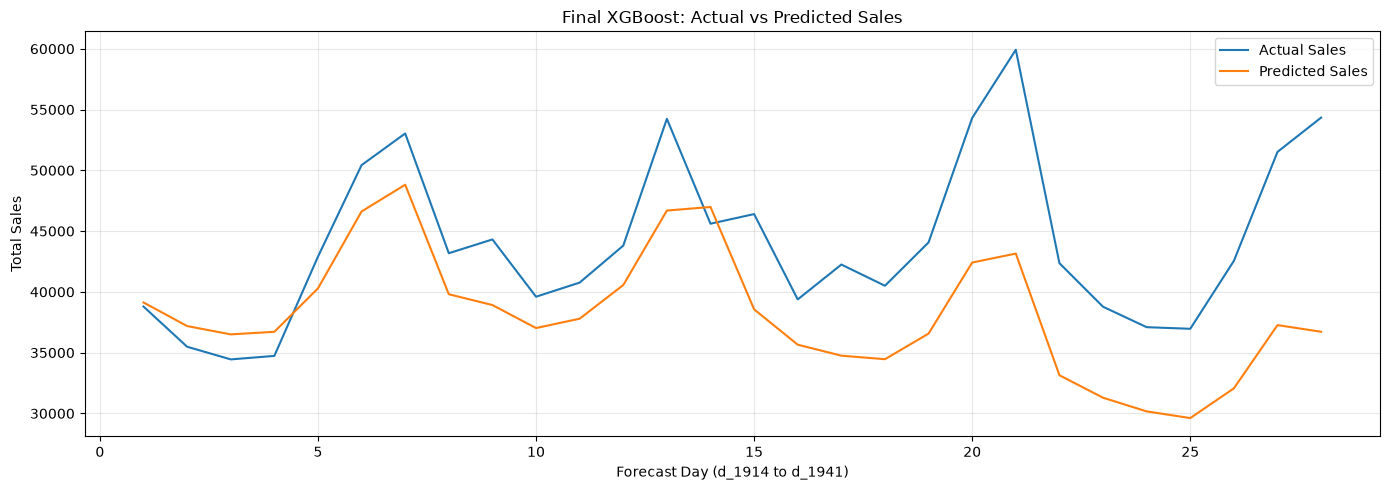

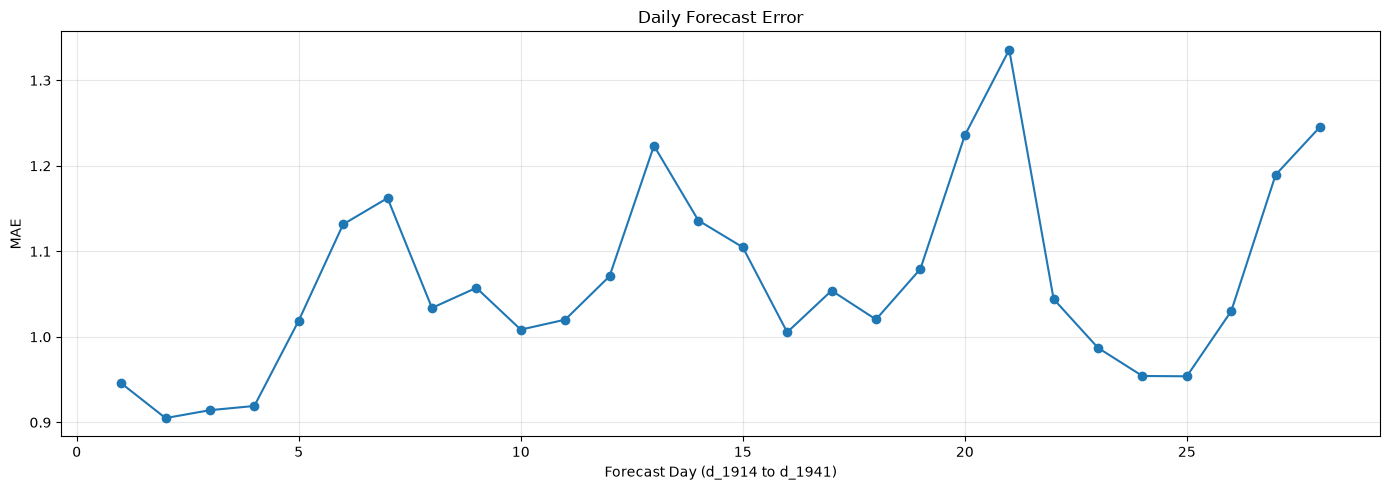

Overall MAE: 1.0638
Average daily MAE: 1.0638
Forecast shape: (853720, 4)
Saved forecast: data/model_ready/final_forecast_d1914_d1941.parquet


In [55]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Daily total actual vs predicted sales
daily_results = (
    forecast_df.groupby("d", as_index=False)
    .agg(
        actual_sales=("actual_sales", "sum"),
        predicted_sales=("predicted_sales", "sum")
    )
)

days = np.arange(1, len(daily_results) + 1)

plt.figure(figsize=(14, 5))
plt.plot(days, daily_results["actual_sales"], label="Actual Sales")
plt.plot(days, daily_results["predicted_sales"], label="Predicted Sales")
plt.xlabel("Forecast Day (d_1914 to d_1941)")
plt.ylabel("Total Sales")
plt.title("Final XGBoost: Actual vs Predicted Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Daily MAE
daily_results["MAE"] = [
    mean_absolute_error(
        forecast_df.loc[forecast_df["d"] == d, "actual_sales"],
        forecast_df.loc[forecast_df["d"] == d, "predicted_sales"]
    )
    for d in daily_results["d"]
]

plt.figure(figsize=(14, 5))
plt.plot(days, daily_results["MAE"], marker="o")
plt.xlabel("Forecast Day (d_1914 to d_1941)")
plt.ylabel("MAE")
plt.title("Daily Forecast Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Overall MAE:", round(final_mae, 4))
print("Average daily MAE:", round(daily_results["MAE"].mean(), 4))
print("Forecast shape:", forecast_df.shape)
print("Saved forecast: data/model_ready/final_forecast_d1914_d1941.parquet")

# XGBoost Model — Initial Evaluation Report

**Forecasting period:** `d_1914` to `d_1941` (28 days)

**Current results:**
- MAE: 1.0629
- RMSE: 2.1628
- WAPE: 73.67%
- WAPE-based score: 26.33%

**Observation:** XGBoost performed slightly better than the Moving Average 28 baseline (MAE 1.0641), but the improvement was very small. The current forecasting errors indicate that the model needs further improvement.

**Next objective:** Investigate prediction errors and improve the model's features and forecasting process without unnecessarily repeating expensive training.

**Proposed target:** Reduce MAE to **0.95 or lower**, then verify the improvement on the same 28-day evaluation period and compare against the baseline.

In [56]:
current_mae = 1.0629
target_mae = 0.95
baseline_mae = 1.0641

improvement_needed = (current_mae - target_mae) / current_mae * 100

print(f"Current XGBoost MAE: {current_mae:.4f}")
print(f"Moving Average 28 MAE: {baseline_mae:.4f}")
print(f"Target MAE: {target_mae:.4f}")
print(f"Improvement needed: {improvement_needed:.2f}%")

if current_mae <= target_mae:
    print("Target achieved!")
else:
    print("Target not achieved yet. Error diagnosis is the next step.")

Current XGBoost MAE: 1.0629
Moving Average 28 MAE: 1.0641
Target MAE: 0.9500
Improvement needed: 10.62%
Target not achieved yet. Error diagnosis is the next step.


XGBOOST feature importance

Top 15 Important Features:
             Feature   Importance
         roll_mean_7 3.181875e+06
        roll_mean_28 1.068657e+06
               lag_1 4.329136e+05
         roll_std_28 2.097999e+05
               lag_7 2.091556e+05
          roll_std_7 2.064943e+05
              lag_14 5.508259e+04
       zero_ratio_28 5.198996e+04
              lag_28 3.941861e+04
     price_available 2.694103e+04
days_since_last_sale 1.453867e+04
          sell_price 1.453414e+04
              lag_56 1.453153e+04
                wday 1.345912e+04
         day_of_week 1.067131e+04


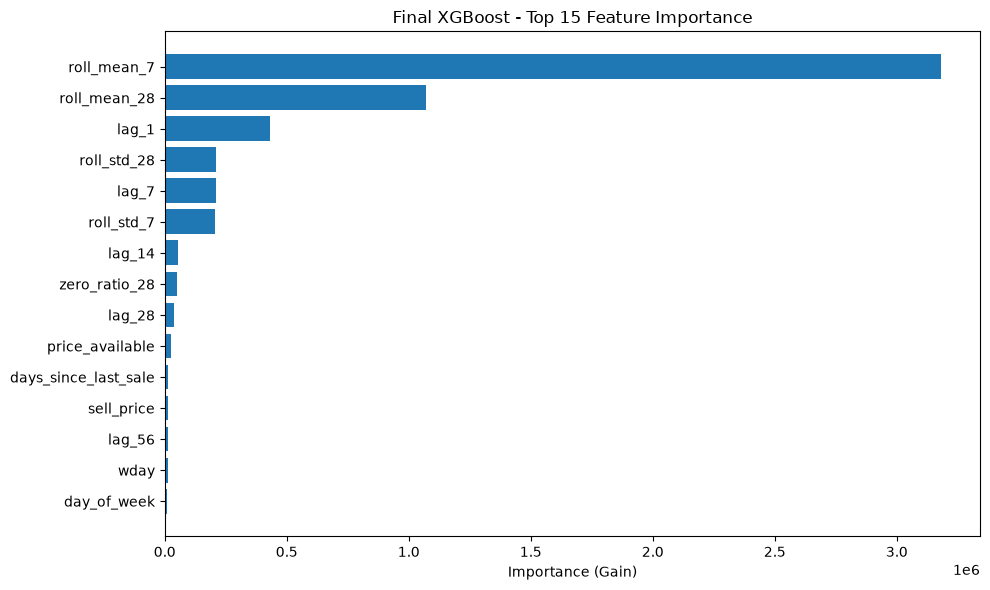

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Feature importance from the already-trained final XGBoost model
importance_scores = xgb_model_final.get_score(importance_type="gain")

feature_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": [
        importance_scores.get(f"f{i}", 0)
        for i in range(len(FEATURES))
    ]
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15).to_string(index=False))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance (Gain)")
plt.title("Final XGBoost - Top 15 Feature Importance")
plt.tight_layout()
plt.show()

Recursive forcasting features

In [58]:
# Check the dynamic features used by the final model
dynamic_features = [
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
    "roll_mean_7", "roll_std_7",
    "roll_mean_28", "roll_std_28",
    "zero_ratio_7", "zero_ratio_28",
    "days_since_last_sale"
]

print("Dynamic features present in model:")
for feature in dynamic_features:
    print(f"{feature}: {'Yes' if feature in FEATURES else 'No'}")

print("\nTop 5 features by importance:")
print(feature_importance.head(5).to_string(index=False))

Dynamic features present in model:
lag_1: Yes
lag_7: Yes
lag_14: Yes
lag_28: Yes
lag_56: Yes
roll_mean_7: Yes
roll_std_7: Yes
roll_mean_28: Yes
roll_std_28: Yes
zero_ratio_7: Yes
zero_ratio_28: Yes
days_since_last_sale: Yes

Top 5 features by importance:
     Feature   Importance
 roll_mean_7 3.181875e+06
roll_mean_28 1.068657e+06
       lag_1 4.329136e+05
 roll_std_28 2.097999e+05
       lag_7 2.091556e+05


In [59]:
# Check the last 5 days of actual vs predicted total sales
daily_check = (
    forecast_df.groupby("d", as_index=False)
    .agg(
        actual=("actual_sales", "sum"),
        predicted=("predicted_sales", "sum")
    )
)

daily_check["error"] = daily_check["predicted"] - daily_check["actual"]
daily_check["abs_error"] = daily_check["error"].abs()

print(daily_check.tail(10).round(2).to_string(index=False))

# Check if errors increase over the forecast horizon
daily_check["forecast_day"] = range(1, len(daily_check) + 1)

daily_check["period"] = pd.cut(
    daily_check["forecast_day"],
    bins=[0, 7, 14, 21, 28],
    labels=["Days 1-7", "Days 8-14", "Days 15-21", "Days 22-28"]
)

print("\nAverage absolute error by forecast week:")
print(
    daily_check.groupby("period", observed=True)["abs_error"]
    .mean()
    .round(2)
)

     d  actual    predicted         error    abs_error
d_1932 44073.0 36567.078125  -7505.910156  7505.910156
d_1933 54308.0 42414.441406 -11893.559570 11893.559570
d_1934 59921.0 43151.238281 -16769.759766 16769.759766
d_1935 42362.0 33141.289062  -9220.709961  9220.709961
d_1936 38777.0 31291.320312  -7485.680176  7485.680176
d_1937 37096.0 30168.029297  -6927.970215  6927.970215
d_1938 36963.0 29616.570312  -7346.430176  7346.430176
d_1939 42552.0 32063.279297 -10488.719727 10488.719727
d_1940 51518.0 37266.500000 -14251.500000 14251.500000
d_1941 54338.0 36718.511719 -17619.490234 17619.490234

Average absolute error by forecast week:
period
Days 1-7       2388.510010
Days 8-14      3783.840088
Days 15-21     8752.830078
Days 22-28    10477.209961
Name: abs_error, dtype: float32


In [60]:
# Verify days_since_last_sale calculation
test_history = np.zeros(56)
test_history[-1] = 1  # Sale yesterday

nonzero = np.where(test_history > 0)[0]

old_value = 56 if len(nonzero) == 0 else 55 - nonzero[-1]
correct_value = 56 if len(nonzero) == 0 else 56 - nonzero[-1]

print("Old calculation:", old_value)
print("Expected calculation:", correct_value)


# Check the latest forecast row's dynamic features
# and compare them with features reconstructed from history.

Old calculation: 0
Expected calculation: 1


In [61]:
# Check the latest forecast row's dynamic features
# and compare them with features reconstructed from history.

day = 1914
day_name = f"d_{day}"

check_df = future_df[future_df["d"] == day_name].head(5).copy()

check_ids = check_df["id"].tolist()
recent_cols = [f"d_{i}" for i in range(day - 56, day)]

recent = history_wide.reindex(
    index=check_ids, columns=recent_cols
).fillna(0).to_numpy(dtype=np.float32)

reconstructed = pd.DataFrame({
    "id": check_ids,
    "lag_1": recent[:, -1],
    "lag_7": recent[:, -7],
    "lag_14": recent[:, -14],
    "lag_28": recent[:, -28],
    "lag_56": recent[:, 0],
    "roll_mean_7": recent[:, -7:].mean(axis=1),
    "roll_mean_28": recent[:, -28:].mean(axis=1),
    "zero_ratio_7": (recent[:, -7:] == 0).mean(axis=1),
    "zero_ratio_28": (recent[:, -28:] == 0).mean(axis=1),
    "days_since_last_sale": [
        56 if not np.any(row > 0)
        else 56 - np.where(row > 0)[0][-1]
        for row in recent
    ]
})

print("Reconstructed features for first 5 series:")
print(reconstructed.round(3).to_string(index=False))

Reconstructed features for first 5 series:
                         id  lag_1  lag_7  lag_14  lag_28  lag_56  roll_mean_7  roll_mean_28  zero_ratio_7  zero_ratio_28  days_since_last_sale
FOODS_1_001_CA_1_evaluation    0.0    4.0     2.0     2.0     1.0        1.143         1.179         0.286          0.357                     2
FOODS_1_001_CA_2_evaluation    4.0    0.0     0.0     0.0     0.0        1.429         1.107         0.429          0.643                     1
FOODS_1_001_CA_3_evaluation    0.0    0.0     1.0     0.0     1.0        0.143         0.857         0.857          0.714                     2
FOODS_1_001_CA_4_evaluation    1.0    2.0     0.0     2.0     0.0        0.714         0.321         0.429          0.750                     1
FOODS_1_001_TX_1_evaluation    0.0    0.0     0.0     0.0     0.0        0.000         0.036         1.000          0.964                    20


In [62]:
# Compare original vs reconstructed features for d_1914
day_name = "d_1914"

original = future_df[future_df["d"] == day_name].copy()

compare_cols = [
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
    "roll_mean_7", "roll_mean_28",
    "zero_ratio_7", "zero_ratio_28",
    "days_since_last_sale"
]

original = original.set_index("id")

comparison = original[compare_cols].join(
    reconstructed.set_index("id")[compare_cols],
    lsuffix="_original",
    rsuffix="_reconstructed"
)

for col in compare_cols:
    comparison[f"{col}_match"] = np.isclose(
        comparison[f"{col}_original"],
        comparison[f"{col}_reconstructed"],
        equal_nan=True
    )

print("Feature mismatch counts:")
for col in compare_cols:
    print(
        f"{col}: "
        f"{(~comparison[f'{col}_match']).sum()} mismatches"
    )

Feature mismatch counts:
lag_1: 30485 mismatches
lag_7: 30485 mismatches
lag_14: 30485 mismatches
lag_28: 30485 mismatches
lag_56: 30485 mismatches
roll_mean_7: 30485 mismatches
roll_mean_28: 30485 mismatches
zero_ratio_7: 30485 mismatches
zero_ratio_28: 30485 mismatches
days_since_last_sale: 30485 mismatches


In [63]:
# Verify dynamic features for ALL series on d_1914

day_name = "d_1914"
day_num = 1914

original = (
    future_df[future_df["d"] == day_name]
    .set_index("id")
)

ids = original.index.tolist()
recent_cols = [f"d_{i}" for i in range(day_num - 56, day_num)]

recent = history_wide.reindex(
    index=ids, columns=recent_cols
).fillna(0).to_numpy(dtype=np.float32)

reconstructed_all = pd.DataFrame({
    "id": ids,
    "lag_1": recent[:, -1],
    "lag_7": recent[:, -7],
    "lag_14": recent[:, -14],
    "lag_28": recent[:, -28],
    "lag_56": recent[:, 0],
    "roll_mean_7": recent[:, -7:].mean(axis=1),
    "roll_std_7": recent[:, -7:].std(axis=1),
    "roll_mean_28": recent[:, -28:].mean(axis=1),
    "roll_std_28": recent[:, -28:].std(axis=1),
    "zero_ratio_7": (recent[:, -7:] == 0).mean(axis=1),
    "zero_ratio_28": (recent[:, -28:] == 0).mean(axis=1),
    "days_since_last_sale": [
        56 if not np.any(row > 0)
        else 56 - np.where(row > 0)[0][-1]
        for row in recent
    ]
}).set_index("id")

check_cols = [
    c for c in reconstructed_all.columns
    if c in FEATURES
]

print("Mismatch counts across all series:")

for col in check_cols:
    a = original.loc[ids, col].to_numpy(dtype=float)
    b = reconstructed_all.loc[ids, col].to_numpy(dtype=float)

    mismatch = ~np.isclose(
        a, b, equal_nan=True, atol=1e-5
    )

    print(f"{col}: {mismatch.sum():,}")

Mismatch counts across all series:
lag_1: 0
lag_7: 0
lag_14: 0
lag_28: 0
lag_56: 0
roll_mean_7: 0
roll_std_7: 25,596
roll_mean_28: 0
roll_std_28: 28,903
zero_ratio_7: 0
zero_ratio_28: 0
days_since_last_sale: 995


In [64]:
for col in ["roll_std_7", "roll_std_28", "days_since_last_sale"]:
    a = original[col].to_numpy(dtype=float)
    b = reconstructed_all[col].to_numpy(dtype=float)

    diff = np.abs(a - b)

    print(f"\n{col}")
    print("Mean absolute difference:", round(np.nanmean(diff), 6))
    print("Maximum difference:", round(np.nanmax(diff), 6))
    print("Original sample:", a[:5])
    print("Reconstructed sample:", b[:5])


roll_std_7
Mean absolute difference: 0.082055
Maximum difference: 2.921633
Original sample: [1.34518542 1.81265393 0.37796447 0.75592895 0.        ]
Reconstructed sample: [1.24539983 1.67819142 0.3499271  0.6998542  0.        ]

roll_std_28
Mean absolute difference: 0.022692
Maximum difference: 0.719385
Original sample: [1.2781228  2.76672404 2.53441915 0.61183219 0.18898224]
Reconstructed sample: [1.25509167 2.71686912 2.48875022 0.60080725 0.18557689]

days_since_last_sale
Mean absolute difference: 2.350344
Maximum difference: 1607.0
Original sample: [ 2.  1.  2.  1. 20.]
Reconstructed sample: [ 2.  1.  2.  1. 20.]


In [65]:
# Compare both standard deviation conventions
for window, col in [(7, "roll_std_7"), (28, "roll_std_28")]:
    values = recent[:, -window:]

    std_ddof0 = values.std(axis=1, ddof=0)
    std_ddof1 = values.std(axis=1, ddof=1)

    original_values = original[col].to_numpy(dtype=float)

    error0 = np.mean(np.abs(original_values - std_ddof0))
    error1 = np.mean(np.abs(original_values - std_ddof1))

    print(f"\n{col}")
    print(f"Error with ddof=0: {error0:.6f}")
    print(f"Error with ddof=1: {error1:.6f}")


roll_std_7
Error with ddof=0: 0.082055
Error with ddof=1: 0.000000

roll_std_28
Error with ddof=0: 0.022692
Error with ddof=1: 0.000000


In [66]:
# Find series where days_since_last_sale differs

original_days = original["days_since_last_sale"].to_numpy(dtype=float)

reconstructed_days = reconstructed_all[
    "days_since_last_sale"
].to_numpy(dtype=float)

diff_mask = ~np.isclose(
    original_days,
    reconstructed_days,
    equal_nan=True
)

print("Total mismatches:", diff_mask.sum())

# Inspect first 10 mismatches
mismatch_ids = original.index[diff_mask][:10]

days_check = pd.DataFrame({
    "original": original.loc[
        mismatch_ids, "days_since_last_sale"
    ],
    "reconstructed": reconstructed_all.loc[
        mismatch_ids, "days_since_last_sale"
    ]
})

print(days_check.to_string())

Total mismatches: 995
                             original  reconstructed
id                                                  
FOODS_1_004_CA_1_evaluation      80.0             56
FOODS_1_004_CA_2_evaluation      82.0             56
FOODS_1_004_CA_4_evaluation      87.0             56
FOODS_1_004_TX_1_evaluation      77.0             56
FOODS_1_004_TX_2_evaluation      86.0             56
FOODS_1_004_TX_3_evaluation      81.0             56
FOODS_1_004_WI_1_evaluation      83.0             56
FOODS_1_004_WI_2_evaluation      77.0             56
FOODS_1_004_WI_3_evaluation      81.0             56
FOODS_1_009_CA_1_evaluation      81.0             56


In [67]:
# Inspect original days_since_last_sale distribution

print("Original feature statistics:")
print(original["days_since_last_sale"].describe())

print("\nValues greater than 56:")
print((original["days_since_last_sale"] > 56).sum())

print("\nLargest original values:")
print(
    original["days_since_last_sale"]
    .sort_values(ascending=False)
    .head(10)
)

Original feature statistics:
count    30490.000000
mean         8.068055
std         32.028534
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max       1663.000000
Name: days_since_last_sale, dtype: float64

Values greater than 56:
995

Largest original values:
id
FOODS_2_394_TX_3_evaluation        1663.0
HOBBIES_1_335_WI_1_evaluation      1030.0
FOODS_2_129_TX_3_evaluation         959.0
HOBBIES_1_335_WI_3_evaluation       941.0
HOBBIES_1_335_TX_1_evaluation       935.0
HOBBIES_1_335_CA_3_evaluation       917.0
HOBBIES_1_335_WI_2_evaluation       882.0
HOBBIES_1_210_CA_1_evaluation       809.0
HOUSEHOLD_1_356_CA_4_evaluation     804.0
HOUSEHOLD_1_356_CA_3_evaluation     782.0
Name: days_since_last_sale, dtype: float64


In [68]:
#verify days_since_last_sale for d_1914
cutoff = dset.to_table(
    columns=["id", "sales", "days_since_last_sale"],
    filter=ds.field("d") == "d_1913"
).to_pandas().set_index("id")

last_sale = 1913 - cutoff["days_since_last_sale"]
last_sale.loc[cutoff["sales"] > 0] = 1913

expected = 1914 - last_sale

original_day = (
    future_df[future_df["d"] == "d_1914"]
    .set_index("id")["days_since_last_sale"]
)

comparison = pd.concat(
    [
        original_day.rename("original"),
        expected.rename("reconstructed")
    ],
    axis=1
).dropna()

mismatch = ~np.isclose(
    comparison["original"],
    comparison["reconstructed"]
)

print("Series compared:", len(comparison))
print("Mismatches:", mismatch.sum())
print(
    "Mismatch percentage:",
    round(mismatch.mean() * 100, 2),
    "%"
)

Series compared: 30490
Mismatches: 0
Mismatch percentage: 0.0 %


In [69]:
print("validation model available:","xgb_model" in globals())
print("Validation data available:","val_rec" in globals())
print("Validation history available:","hist" in globals())

validation model available: True
Validation data available: True
Validation history available: True


## Final recursive XGBoost validation (d_1886-d_1913)

The training feature `days_since_last_sale` is the number of calendar days since the previous positive sale, with no 56-day cap. Training uses `-1` only when a series has never sold; `no_previous_sale` marks that same state. Validation must preserve both meanings.

Issues found in the earlier recursive drafts:

- One version writes predictions into history after the day loop, so only the last day's predictions can feed the next day.
- Other versions calculate days since sale from only 56 days of history; their `55 - index` formula is also one day too small. Both differ from training for gaps over 56 days and for a sale yesterday.
- The draft initialized from `d_1885` can turn the `-1` never-sold sentinel into a future sale date. The draft initialized from `d_1886` needs to preserve the `no_previous_sale` state explicitly.
- The dynamic `no_previous_sale` feature must be rebuilt from recursive prediction state; keeping its validation value would expose actual future sales. Rolling standard deviations must use the training convention (`ddof=1`).
- Threshold updates belong inside the day loop and must test each prediction against the current threshold.

The code below supersedes the threshold-validation drafts. It uses identical dates and series for all three thresholds, updates history only with predictions, and returns overall metrics, day-1-to-day-28 MAE, and row-level actual/prediction comparisons. It does not retrain or alter the XGBoost model. Run it after `xgb_model`, `val_rec`, `hist`, and `FEATURES` are available.

In [ ]:
import numpy as np
import pandas as pd


def recursive_xgb_validation(xgb_model, val_rec, hist, feature_names):
    """Evaluate d_1886-d_1913 recursively for thresholds 0.0, 0.5, and 1.0."""
    start_day, end_day = 1886, 1913
    validation_days = [f"d_{day}" for day in range(start_day, end_day + 1)]
    history_days = [f"d_{day}" for day in range(start_day - 56, start_day)]
    thresholds = (0.0, 0.5, 1.0)
    dynamic_features = {
        "lag_1", "lag_7", "lag_14", "lag_28", "lag_56",
        "roll_mean_7", "roll_std_7", "roll_mean_28", "roll_std_28",
        "zero_ratio_7", "zero_ratio_28", "days_since_last_sale",
        "no_previous_sale",
    }

    feature_names = list(feature_names)
    if len(feature_names) != len(set(feature_names)):
        raise ValueError("FEATURES contains duplicate feature names.")
    if not dynamic_features.issubset(feature_names):
        missing = sorted(dynamic_features.difference(feature_names))
        raise ValueError(f"FEATURES is missing dynamic features: {missing}")

    required_val = {"id", "d", "sales"}.union(feature_names)
    missing_val = sorted(required_val.difference(val_rec.columns))
    if missing_val:
        raise ValueError(f"Validation data is missing columns: {missing_val}")
    if val_rec.duplicated(["id", "d"]).any():
        raise ValueError("Validation data has duplicate (id, d) rows.")
    if set(val_rec["d"].unique()) != set(validation_days):
        raise ValueError("Validation data must contain exactly d_1886 through d_1913.")

    ids_by_day = {
        day_name: set(val_rec.loc[val_rec["d"] == day_name, "id"])
        for day_name in validation_days
    }
    series_ids = val_rec.loc[val_rec["d"] == validation_days[0], "id"].tolist()
    if not series_ids or any(ids != set(series_ids) for ids in ids_by_day.values()):
        raise ValueError("Every validation day must contain the same non-empty series set.")

    required_hist = {"id", "d", "sales"}
    missing_hist = sorted(required_hist.difference(hist.columns))
    if missing_hist:
        raise ValueError(f"Historical data is missing columns: {missing_hist}")
    history_slice = hist.loc[
        hist["d"].isin(history_days), ["id", "d", "sales"]
    ].copy()
    if history_slice.duplicated(["id", "d"]).any():
        raise ValueError("Historical data has duplicate (id, d) rows.")

    history_wide = history_slice.pivot(index="id", columns="d", values="sales")
    missing_history_days = sorted(set(history_days).difference(history_wide.columns))
    if missing_history_days:
        raise ValueError(f"Historical data is missing required days: {missing_history_days}")
    history_wide = history_wide.reindex(index=series_ids, columns=history_days)
    if history_wide.isna().any().any():
        raise ValueError("Historical sales have missing values for validation series/days.")
    history_base = history_wide.copy()

    first_day = (
        val_rec.loc[val_rec["d"] == validation_days[0]]
        .set_index("id")
        .reindex(series_ids)
    )
    initial_days_since = pd.to_numeric(
        first_day["days_since_last_sale"], errors="raise"
    )
    initial_no_previous = pd.to_numeric(
        first_day["no_previous_sale"], errors="raise"
    )
    if initial_days_since.isna().any() or initial_no_previous.isna().any():
        raise ValueError("The first validation day's sale-history features contain missing values.")
    if not initial_no_previous.isin([0, 1]).all():
        raise ValueError("no_previous_sale must contain only 0 or 1.")
    never_sold = initial_no_previous.eq(1)
    if not (initial_days_since.loc[never_sold] == -1).all():
        raise ValueError("Training sentinel mismatch: never-sold series must have days_since_last_sale=-1.")
    if not (initial_days_since.loc[~never_sold] >= 1).all():
        raise ValueError("Previously-sold series must have days_since_last_sale >= 1.")

    # Seed from d_1886's pre-day features, which summarize actual history only through d_1885.
    last_sale_day = pd.Series(np.nan, index=series_ids, dtype=np.float64)
    has_previous_sale = ~never_sold
    last_sale_day.loc[has_previous_sale] = (
        start_day - initial_days_since.loc[has_previous_sale].astype(np.float64)
    )

    summary_rows = []
    horizon_rows = []
    prediction_frames = []

    for threshold in thresholds:
        history = history_base.copy()
        last_sale = last_sale_day.copy()
        actual_by_day = []
        prediction_by_day = []
        prediction_rows = []
        predicted_sale_days = 0

        for horizon, day in enumerate(range(start_day, end_day + 1), start=1):
            day_name = f"d_{day}"
            day_df = (
                val_rec.loc[val_rec["d"] == day_name]
                .set_index("id")
                .reindex(series_ids)
                .reset_index()
                .copy()
            )
            ids = day_df["id"].tolist()
            recent_days = [f"d_{value}" for value in range(day - 56, day)]
            recent = history.loc[ids, recent_days].to_numpy(dtype=np.float32)

            last_sale_today = last_sale.loc[ids]
            has_sale = last_sale_today.notna().to_numpy()
            days_since = np.full(len(ids), -1.0, dtype=np.float32)
            last_sale_values = last_sale_today.to_numpy(dtype=np.float64)
            days_since[has_sale] = day - last_sale_values[has_sale]

            dynamic_values = {
                "lag_1": recent[:, -1],
                "lag_7": recent[:, -7],
                "lag_14": recent[:, -14],
                "lag_28": recent[:, -28],
                "lag_56": recent[:, 0],
                "roll_mean_7": recent[:, -7:].mean(axis=1),
                "roll_std_7": recent[:, -7:].std(axis=1, ddof=1),
                "roll_mean_28": recent[:, -28:].mean(axis=1),
                "roll_std_28": recent[:, -28:].std(axis=1, ddof=1),
                "zero_ratio_7": (recent[:, -7:] == 0).mean(axis=1),
                "zero_ratio_28": (recent[:, -28:] == 0).mean(axis=1),
                "days_since_last_sale": days_since,
                "no_previous_sale": (~has_sale).astype(np.int8),
            }
            for name, values in dynamic_values.items():
                day_df[name] = values

            actual = pd.to_numeric(day_df["sales"], errors="raise").to_numpy(dtype=np.float64)
            if not np.isfinite(actual).all():
                raise ValueError(f"Actual sales contain non-finite values on {day_name}.")
            X_day = day_df.loc[:, feature_names].to_numpy(dtype=np.float32)
            prediction = np.asarray(xgb_model.predict(X_day), dtype=np.float64).reshape(-1)
            if len(prediction) != len(ids) or not np.isfinite(prediction).all():
                raise ValueError(f"Model returned invalid predictions on {day_name}.")
            prediction = np.maximum(prediction, 0.0)

            # The same threshold mask is recorded and used to update recursive sale state.
            update_last_sale = prediction > threshold
            predicted_sale_days += int(update_last_sale.sum())
            prediction_error = prediction - actual
            horizon_rows.append({
                "Threshold": threshold,
                "Horizon": horizon,
                "Day": day_name,
                "MAE": float(np.mean(np.abs(prediction_error))),
            })
            prediction_rows.append(pd.DataFrame({
                "Threshold": np.full(len(ids), threshold, dtype=np.float32),
                "Horizon": np.full(len(ids), horizon, dtype=np.int8),
                "Day": day_name,
                "id": ids,
                "Actual": actual.astype(np.float32),
                "Prediction": prediction.astype(np.float32),
                "LastSaleUpdated": update_last_sale,
            }))
            actual_by_day.append(actual)
            prediction_by_day.append(prediction)

            # Feed predictions, never validation actuals, into the next day's history.
            history[day_name] = np.nan
            history.loc[ids, day_name] = prediction
            last_sale.loc[np.asarray(ids)[update_last_sale]] = day

        all_actual = np.concatenate(actual_by_day)
        all_prediction = np.concatenate(prediction_by_day)
        error = all_prediction - all_actual
        actual_total = float(np.abs(all_actual).sum())
        if actual_total == 0:
            raise ValueError("WAPE is undefined because validation actuals sum to zero.")
        summary_rows.append({
            "Threshold": threshold,
            "MAE": float(np.mean(np.abs(error))),
            "RMSE": float(np.sqrt(np.mean(np.square(error)))),
            "WAPE_pct": float(100.0 * np.abs(error).sum() / actual_total),
            "PredictionBias": float(np.mean(error)),
            "PredictedSaleDays": predicted_sale_days,
        })
        prediction_frames.append(pd.concat(prediction_rows, ignore_index=True))

    summary = pd.DataFrame(summary_rows)
    horizon_mae = pd.DataFrame(horizon_rows)
    prediction_comparison = pd.concat(prediction_frames, ignore_index=True)
    prediction_comparison["id"] = prediction_comparison["id"].astype("category")
    prediction_comparison["Day"] = pd.Categorical(
        prediction_comparison["Day"], categories=validation_days, ordered=True
    )
    prediction_comparison["Threshold"] = pd.Categorical(
        prediction_comparison["Threshold"], categories=thresholds, ordered=True
    )
    return summary, horizon_mae, prediction_comparison


validation_summary, horizon_mae, validation_predictions = recursive_xgb_validation(
    xgb_model=xgb_model,
    val_rec=val_rec,
    hist=hist,
    feature_names=FEATURES,
)

print("Overall recursive validation metrics (same d_1886-d_1913 dates and series):")
print(validation_summary.to_string(index=False))
print("\nMAE by forecast horizon:")
print(horizon_mae.to_string(index=False))
print("\nActual vs prediction examples (full comparison is in validation_predictions):")
print(validation_predictions.head(10).to_string(index=False))

In [1]:
import numpy as np
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

error = forecast["predicted_sales"] - forecast["actual_sales"]

print("Forecast days:", forecast["d"].min(), "to", forecast["d"].max())
print("Rows:", len(forecast))
print("MAE:", np.abs(error).mean())
print("RMSE:", np.sqrt(np.square(error).mean()))
print("WAPE %:", 100 * np.abs(error).sum() / np.abs(forecast["actual_sales"]).sum())
print("Mean bias:", error.mean())

Forecast days: d_1914 to d_1941
Rows: 853720
MAE: 1.0638025
RMSE: 2.2941597
WAPE %: 73.730804
Mean bias: -0.19082648


In [2]:
parts = forecast["id"].str.split("_")

forecast["department"] = parts.str[0] + "_" + parts.str[1]
forecast["error"] = forecast["predicted_sales"] - forecast["actual_sales"]
forecast["absolute_error"] = forecast["error"].abs()
forecast["squared_error"] = forecast["error"] ** 2

by_department = forecast.groupby("department").agg(
    rows=("id", "size"),
    actual_sales=("actual_sales", "sum"),
    total_absolute_error=("absolute_error", "sum"),
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean"),
    Bias=("error", "mean"),
)

by_department["RMSE"] = np.sqrt(by_department.pop("MSE"))
by_department["WAPE_%"] = (
    100 * by_department["total_absolute_error"] / by_department["actual_sales"]
)
by_department["share_of_total_error_%"] = (
    100 * by_department["total_absolute_error"]
    / by_department["total_absolute_error"].sum()
)

print(
    by_department.sort_values("share_of_total_error_%", ascending=False)
    .round(3)
    .to_string()
)

               rows   actual_sales  total_absolute_error    MAE   Bias   RMSE      WAPE_%  share_of_total_error_%
department                                                                                                       
FOODS_3      230440  564926.000000         350120.062500  1.519 -0.392  3.348   61.976002               38.550999
HOUSEHOLD_1  148960  222327.015625         158235.359375  1.062 -0.159  1.841   71.171997               17.423000
FOODS_2      111440  165203.015625         123621.703125  1.109 -0.192  1.970   74.830002               13.612000
HOBBIES_1    116480  102554.000000         101800.218750  0.874 -0.033  1.873   99.264999               11.209000
FOODS_1       60480  102359.000000          80493.781250  1.331 -0.417  2.673   78.639000                8.863000
HOUSEHOLD_2  144200   61093.000000          74264.921875  0.515  0.007  0.847  121.559998                8.177000
HOBBIES_2     41720   13302.000000          19653.410156  0.471  0.015  0.833  147.74800

In [3]:
import numpy as np
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

history_days = [f"d_{day}" for day in range(1886, 1914)]
history = pd.read_csv(
    "data/raw/sales_train_evaluation.csv",
    usecols=["id"] + history_days,
)

# One fixed 28-day average per item/store series, repeated across forecast days
baseline = (
    history.set_index("id")[history_days]
    .mean(axis=1)
    .rename("baseline_28d")
)

comparison = forecast.join(baseline, on="id")

def score(actual, predicted):
    error = predicted - actual
    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.square(error).mean()),
        "WAPE_%": 100 * np.abs(error).sum() / np.abs(actual).sum(),
        "Bias": error.mean(),
    }

actual = comparison["actual_sales"]

results = pd.DataFrame({
    "XGBoost": score(actual, comparison["predicted_sales"]),
    "28-day average": score(actual, comparison["baseline_28d"]),
}).T

print(results.round(4))

                   MAE    RMSE   WAPE_%    Bias
XGBoost         1.0638  2.2942  73.7308 -0.1908
28-day average  1.0657  2.2430  73.8643 -0.0564


In [4]:
def daily_score(group, prediction_col):
    error = group[prediction_col] - group["actual_sales"]
    actual_total = group["actual_sales"].abs().sum()

    return pd.Series({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "WAPE_%": 100 * error.abs().sum() / actual_total,
    })

daily_comparison = comparison.groupby("d").apply(
    lambda group: pd.concat({
        "XGBoost": daily_score(group, "predicted_sales"),
        "28-day average": daily_score(group, "baseline_28d"),
    }, axis=1)
)

print(daily_comparison.round(3).to_string())

                 XGBoost  28-day average
d                                       
d_1914 MAE      0.946000           0.958
       RMSE     1.944000           1.931
       WAPE_%  74.338997          75.314
d_1915 MAE      0.905000           0.942
       RMSE     1.749000           1.812
       WAPE_%  77.755997          80.950
d_1916 MAE      0.914000           0.967
       RMSE     1.789000           1.902
       WAPE_%  80.927002          85.626
d_1917 MAE      0.919000           0.971
       RMSE     1.764000           1.913
       WAPE_%  80.689003          85.245
d_1918 MAE      1.019000           1.010
       RMSE     2.138000           2.043
       WAPE_%  72.429001          71.796
d_1919 MAE      1.132000           1.106
       RMSE     2.348000           2.329
       WAPE_%  68.417000          66.857
d_1920 MAE      1.162000           1.147
       RMSE     2.307000           2.343
       WAPE_%  66.821999          65.931
d_1921 MAE      1.034000           1.022
       RMSE     